# Example 4.3: Loss Curves and Overfitting Detection
**Chapter 4 · Neural Networks for Mechanism Design**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Statement
Train an MLP with **12 hidden neurons** for 600 epochs on `sin(x)` data with Gaussian noise (σ=0.05). Record the training and validation loss curves at each epoch. Evaluate whether overfitting occurs by comparing the MSE_val/MSE_train ratio at the end.

**Objective:** Visually identify the overfitting phenomenon using loss curves and learn to diagnose it using the MSE ratio.

In [1]:
# ── Imports ──
from numpy import *
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.size': 12})

random.seed(10)

# Data with slight noise (simulates real measurements)
x_all = linspace(0, 2*pi, 250).reshape(-1, 1)
y_all = sin(x_all) + random.normal(0, 0.05, x_all.shape)

# 80/20 split
idx = random.permutation(len(x_all))
n_train = int(0.8 * len(x_all))
x_tr, y_tr = x_all[idx[:n_train]], y_all[idx[:n_train]]
x_vl, y_vl = x_all[idx[n_train:]], y_all[idx[n_train:]]

# Neural network (same architecture)
W1 = random.randn(1, 12) * 0.5; b1 = zeros((1, 12))
W2 = random.randn(12, 1) * 0.5; b2 = zeros((1, 1))
lr = 0.008; N_EP = 600
hist_tr, hist_vl = [], []

for ep in range(N_EP):
    H = tanh(x_tr @ W1 + b1); Yp = H @ W2 + b2
    err = Yp - y_tr; mse_t = float(mean(err**2))
    hist_tr.append(mse_t)
    dW2 = H.T @ (2*err/len(x_tr)); db2 = (2*err/len(x_tr)).sum(0)
    dH  = (2*err/len(x_tr)) @ W2.T
    dZ  = dH * (1-H**2)
    dW1 = x_tr.T @ dZ; db1 = dZ.sum(0)
    W2 -= lr*dW2; b2 -= lr*db2; W1 -= lr*dW1; b1 -= lr*db1
    Hv = tanh(x_vl @ W1 + b1); Yv = Hv @ W2 + b2
    hist_vl.append(float(mean((Yv - y_vl)**2)))

print(f'Final training MSE:   {hist_tr[-1]:.5f}')
print(f'Final validation MSE: {hist_vl[-1]:.5f}')
print(f'Val/Train Ratio:      {hist_vl[-1]/hist_tr[-1]:.2f}')
if hist_vl[-1] / hist_tr[-1] > 2.0:
    print('-> Potential overfitting detected')
else:
    print('-> No significant overfitting')



Final training MSE:   0.11232
Final validation MSE: 0.14326
Val/Train Ratio:      1.28
-> No significant overfitting


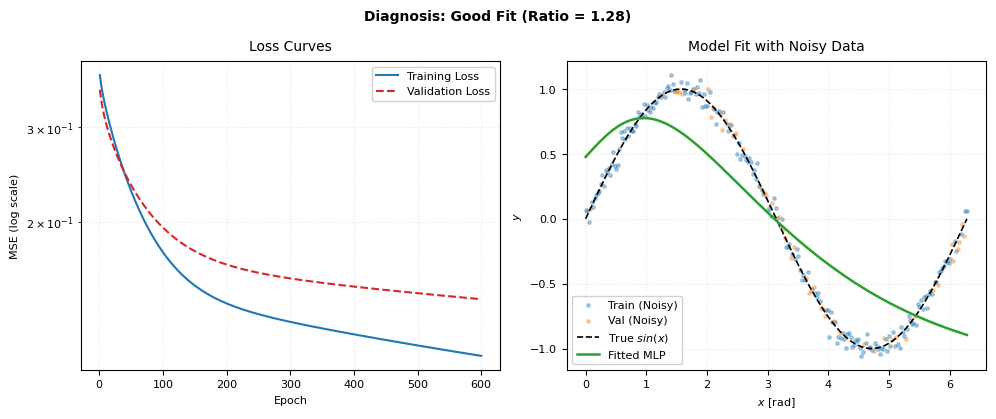

In [3]:
import os
import glob
import matplotlib.pyplot as plt
from numpy import *

# --- Springer Formatting Setup ---
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8
})

# --- Automatic Filename Determination ---
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_4.3_loss_curves_overfitting"
except Exception:
    notebook_name = "Figure_4.3_loss_curves_overfitting"

# --- Figure Creation (12 x 4.5 inches for clean double-column layout) ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# Subplot 0: Loss curves
ep_ax = arange(1, N_EP + 1)
axes[0].semilogy(ep_ax, hist_tr, color='#1f77b4', linestyle='-', lw=1.5, label='Training Loss')
axes[0].semilogy(ep_ax, hist_vl, color='#d62728', linestyle='--', lw=1.5, label='Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE (log scale)')
axes[0].set_title('Loss Curves', pad=8)
axes[0].legend(loc='upper right', frameon=True, framealpha=0.9)
axes[0].grid(True, which='both', linestyle=':', alpha=0.3)

# Subplot 1: Prediction vs actual
x_sort = linspace(0, 2*pi, 300).reshape(-1, 1)
Hp = tanh(x_sort @ W1 + b1)
Yp = Hp @ W2 + b2

axes[1].scatter(x_tr, y_tr, s=6, color='#1f77b4', alpha=0.35, label='Train (Noisy)')
axes[1].scatter(x_vl, y_vl, s=6, color='#ff7f0e', alpha=0.35, label='Val (Noisy)')
axes[1].plot(x_sort, sin(x_sort), 'k--', lw=1.2, label='True $sin(x)$')
axes[1].plot(x_sort, Yp, color='#2ca02c', linestyle='-', lw=1.8, label='Fitted MLP')
axes[1].set_xlabel('$x$ [rad]')
axes[1].set_ylabel('$y$')
axes[1].set_title('Model Fit with Noisy Data', pad=8)
axes[1].legend(loc='lower left', frameon=True, framealpha=0.9)
axes[1].grid(True, linestyle=':', alpha=0.3)

# Diagnostics Text Positioning (Avoid overlapping by using coordinate offsets)
ratio = hist_vl[-1] / hist_tr[-1]
estado = 'Overfitting' if ratio > 2.0 else 'Good Fit'
plt.suptitle(f'Diagnosis: {estado} (Ratio = {ratio:.2f})',
             fontsize=10, fontweight='bold', y=0.98)

plt.tight_layout()

# --- Double Format Export ---
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()